In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, requests, time, statistics, os
from datetime import datetime, timezone

R,D,Q,N,p,H,B,T = 71,3,3275,8,0.07,7,1910,8
print(f"R={R}, D={D}, daily queries={Q}, calls/query={N}, failure chance={p:.0%}, heatwave days={H}, budget=${B}, response target={T}s")

R=71, D=3, daily queries=3275, calls/query=8, failure chance=7%, heatwave days=7, budget=$1910, response target=8s


In [4]:
inputs = np.array([2000+800*(k-1) for k in range(1,N+1)])
outputs = np.array([350]*(N-1)+[600])

expected_input = inputs.sum() + p*inputs[:-1].sum()
expected_output = outputs.sum() + p*outputs[:-1].sum()

# FIXED: (30-H) normal days + H heatwave days with 5x traffic
monthly_queries = (30 - H) * Q + H * 5 * Q
monthly_input = monthly_queries * expected_input
monthly_output = monthly_queries * expected_output

print(f"Input/query: {expected_input:.1f}  Output/query: {expected_output:.1f}")
print(f"Monthly queries: {monthly_queries:,}")
print(f"Monthly input tokens: {monthly_input/1e9:.3f}B")
print(f"Monthly output tokens: {monthly_output/1e6:.1f}M")

Input/query: 40556.0  Output/query: 3221.5
Monthly queries: 189,950
Monthly input tokens: 7.704B
Monthly output tokens: 611.9M


In [5]:
models = [
# Closed-source (6)
("Closed","OpenAI","GPT-4.1 mini",0.40,1.60,0.10,"https://developers.openai.com/api/docs/models/gpt-4.1-mini"),
("Closed","OpenAI","GPT-5.4 mini",0.75,4.50,0.075,"https://developers.openai.com/api/docs/models/gpt-5.4-mini"),
("Closed","Anthropic","Claude Sonnet 4.6",3.00,15.00,None,"https://benchgecko.ai/model/claude-sonnet-4-6"),
("Closed","Anthropic","Claude Haiku 4.5",1.00,5.00,None,"https://playground.roboflow.com/models/compare/claude-4-5-haiku-vs-claude-haiku-5-5"),
("Closed","Google","Gemini 2.5 Flash",0.30,2.50,0.03,"https://www.sim.ai/models/google/gemini-2-5-flash"),
("Closed","Mistral AI","Mistral Small 4",0.10,0.30,None,"https://mistral.ai/pricing"),
# Open-weight (6)
("Open-weight","DeepSeek","DeepSeek V3.2",0.26,0.38,0.13,"https://deepinfra.com/deepseek"),
("Open-weight","Meta","Llama 3.3 70B Instruct",0.10,0.32,None,"https://benchgecko.ai/pricing/arbitrage/llama-3-3-70b-instruct"),
("Open-weight","OpenAI","gpt-oss-120b",0.03,0.15,None,"https://openrouter.ai/compare/google/gemini-2.5-flash/openai/gpt-oss-120b"),
("Open-weight","Mistral","Mistral Small 3.2 24B",0.075,0.20,None,"https://openrouter.ai/compare/deepseek/deepseek-v3.2-exp/mistralai/mistral-small-3.2-24b-instruct"),
("Open-weight","Google","Gemma 3 27B",0.10,0.30,None,"https://futureagi.com/llm-cost-calculator/nebius/google-gemma-3-27b-it/"),
("Open-weight","Microsoft","Phi-4 14B",0.07,0.14,None,"https://openrouter.ai/compare/microsoft/phi-4"),  # verify
]

In [6]:
df = pd.DataFrame(models, columns=["type","provider","model","input_per_million","output_per_million","cached_input_per_million","source"])

def cost(row, cached=False):
    if pd.isna(row.input_per_million) or pd.isna(row.output_per_million):
        return np.nan
    # Total tokens that hit the 1500-token cacheable prefix (including retries)
    # Each call has 1500 tokens that are identical. Retries also carry the same prefix.
    # First 7 calls may retry; call 8 never retries.
    num_cached_calls_per_query = 7 + p * 7  # 7 first-attempt + expected retries
    prefix_tokens_per_query = 1500 * num_cached_calls_per_query
    prefix_monthly = monthly_queries * prefix_tokens_per_query

    if cached and pd.notna(row.cached_input_per_million):
        # Non-cached input = total input - cached prefix
        non_cached_input = monthly_input - prefix_monthly
        icost = (non_cached_input * row.input_per_million + prefix_monthly * row.cached_input_per_million) / 1e6
    else:
        icost = monthly_input * row.input_per_million / 1e6

    ocost = monthly_output * row.output_per_million / 1e6
    return icost + ocost

df["monthly_cost_no_cache_usd"] = df.apply(lambda x: cost(x, False), axis=1)
df["monthly_cost_with_cache_usd"] = df.apply(lambda x: cost(x, True), axis=1)
df["within_budget_no_cache"] = df.monthly_cost_no_cache_usd <= B
df["within_budget_with_cache"] = df.monthly_cost_with_cache_usd <= B

display(df[["type","provider","model","input_per_million","output_per_million","cached_input_per_million","monthly_cost_no_cache_usd","monthly_cost_with_cache_usd","within_budget_no_cache","within_budget_with_cache"]])

,type,provider,model,input_per_million,output_per_million,cached_input_per_million,monthly_cost_no_cache_usd,monthly_cost_with_cache_usd,within_budget_no_cache,within_budget_with_cache
0,Closed,OpenAI,GPT-4.1 mini,0.400,1.60,0.100,4060.523160,3420.296685,False,False
1,Closed,OpenAI,GPT-5.4 mini,0.750,4.50,0.075,8531.366813,7090.857244,False,False
2,Closed,Anthropic,Claude Sonnet 4.6,3.000,15.00,NaN,32289.695475,32289.695475,False,False
3,Closed,Anthropic,Claude Haiku 4.5,1.000,5.00,NaN,10763.231825,10763.231825,False,False
4,Closed,Google,Gemini 2.5 Flash,0.300,2.50,0.030,3840.893472,3264.689645,False,False
5,Closed,Mistral AI,Mistral Small 4,0.100,0.30,NaN,953.938398,953.938398,True,True
6,Open-weight,DeepSeek,DeepSeek V3.2,0.260,0.38,0.130,2235.470264,1958.038791,False,False
7,Open-weight,Meta,Llama 3.3 70B Instruct,0.100,0.32,NaN,966.176876,966.176876,True,True
8,Open-weight,OpenAI,gpt-oss-120b,0.030,0.15,NaN,322.896955,322.896955,True,True
9,Open-weight,Mistral,Mistral Small 3.2 24B,0.075,0.20,NaN,700.155700,700.155700,True,True


In [7]:
peak_qpm = (5*Q*0.35)/120
tokens_per_query = expected_input + expected_output
peak_tpm = peak_qpm * tokens_per_query

print(f"Heatwave queries/day: {5*Q:,}")
print(f"Queries noon-2pm: {5*Q*0.35:,.0f}")
print(f"Peak QPM (average over 2h): {peak_qpm:.2f}")
print(f"Peak TPM: {peak_tpm:,.0f}")

# Rate limit check
rate_limits = {
    "GPT-4.1 mini": {"rpm": 5000, "tpm": 2_000_000},
    "GPT-5.4 mini": {"rpm": 5000, "tpm": 2_000_000},
    "Claude Sonnet 4.6": {"rpm": 50, "tpm": 50_000},
    "Claude Haiku 4.5": {"rpm": 50, "tpm": 50_000},
    "Gemini 2.5 Flash": {"rpm": 15, "tpm": 1_000_000},
    "DeepSeek V3.2": {"rpm": 60, "tpm": 200_000},
    "Llama 3.3 70B (DeepInfra)": {"rpm": 60, "tpm": 200_000},
    "gpt-oss-120b (OpenRouter)": {"rpm": 60, "tpm": 200_000},
    "Mistral Small 3.2 (OpenRouter)": {"rpm": 60, "tpm": 200_000},
    "Gemma 3 27B (Nebius)": {"rpm": 60, "tpm": 200_000},
}

print("\n--- Rate Limit Adequacy ---")
for name, lim in rate_limits.items():
    rpm_ok = peak_qpm <= lim["rpm"]
    tpm_ok = peak_tpm <= lim["tpm"]
    status = "PASS" if (rpm_ok and tpm_ok) else "FAIL"
    print(f"{name}: RPM {peak_qpm:.1f}/{lim['rpm']} {'OK' if rpm_ok else 'EXCEEDED'}, "
          f"TPM {peak_tpm:,.0f}/{lim['tpm']:,} {'OK' if tpm_ok else 'EXCEEDED'} -> {status}")

Heatwave queries/day: 16,375
Queries noon-2pm: 5,731
Peak QPM (average over 2h): 47.76
Peak TPM: 2,090,832

--- Rate Limit Adequacy ---
GPT-4.1 mini: RPM 47.8/5000 OK, TPM 2,090,832/2,000,000 EXCEEDED -> FAIL
GPT-5.4 mini: RPM 47.8/5000 OK, TPM 2,090,832/2,000,000 EXCEEDED -> FAIL
Claude Sonnet 4.6: RPM 47.8/50 OK, TPM 2,090,832/50,000 EXCEEDED -> FAIL
Claude Haiku 4.5: RPM 47.8/50 OK, TPM 2,090,832/50,000 EXCEEDED -> FAIL
Gemini 2.5 Flash: RPM 47.8/15 EXCEEDED, TPM 2,090,832/1,000,000 EXCEEDED -> FAIL
DeepSeek V3.2: RPM 47.8/60 OK, TPM 2,090,832/200,000 EXCEEDED -> FAIL
Llama 3.3 70B (DeepInfra): RPM 47.8/60 OK, TPM 2,090,832/200,000 EXCEEDED -> FAIL
gpt-oss-120b (OpenRouter): RPM 47.8/60 OK, TPM 2,090,832/200,000 EXCEEDED -> FAIL
Mistral Small 3.2 (OpenRouter): RPM 47.8/60 OK, TPM 2,090,832/200,000 EXCEEDED -> FAIL
Gemma 3 27B (Nebius): RPM 47.8/60 OK, TPM 2,090,832/200,000 EXCEEDED -> FAIL


In [8]:
parameters_b = 70
layers, kv_heads, head_dim = 80, 8, 128  # From Llama 3.3 70B config.json [citation:1][citation:8]
# FIXED: longest context in agent loop = call 8 input = 2000 + 800*7 = 7600
longest_context = 7600
gpu_memory_gb, reserve = 80, 0.10
weights = {name: parameters_b * bpp for name, bpp in [("FP16",2),("8-bit",1),("4-bit",0.5)]}
kv_gb = (2*layers*kv_heads*head_dim*longest_context*2)/(1024**3)
usable = gpu_memory_gb * (1 - reserve)
capacity = max(0, int((usable - weights["4-bit"]) / kv_gb))

print(f"Weights: {weights}")
print(f"KV cache/sequence: {kv_gb:.3f} GB")
print(f"Usable GPU memory (after 10% reserve): {usable:.0f} GB")
print(f"Max concurrent sequences (4-bit weights, FP16 KV): {capacity}")
print(f"Config source: Llama 3.3 70B config.json — layers={layers}, kv_heads={kv_heads}, head_dim={head_dim}")

Weights: {'FP16': 140, '8-bit': 70, '4-bit': 35.0}
KV cache/sequence: 2.319 GB
Usable GPU memory (after 10% reserve): 72 GB
Max concurrent sequences (4-bit weights, FP16 KV): 15
Config source: Llama 3.3 70B config.json — layers=80, kv_heads=8, head_dim=128


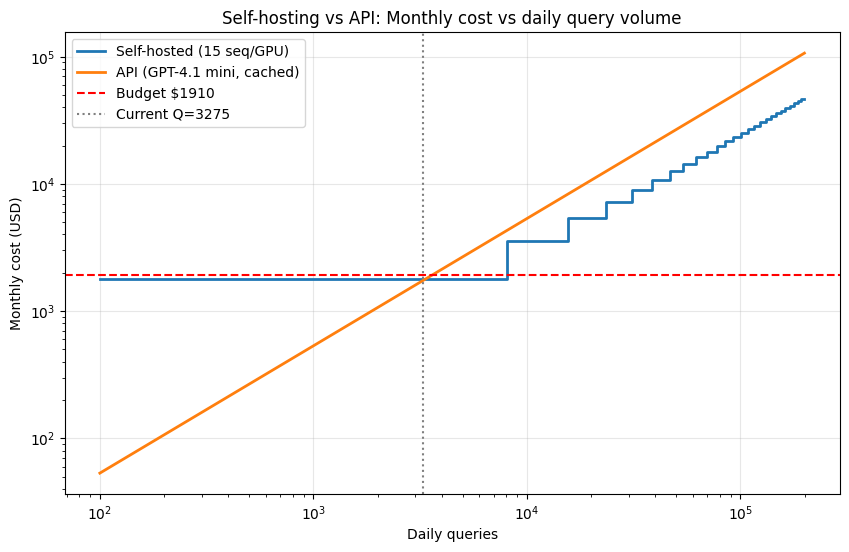

Break-even Q* ≈ 3,600 daily queries


In [9]:
# Real cloud GPU price (Lambda Labs H100 80GB SXM, on-demand, Nov 2026)
gpu_hourly_usd = 2.49  # Lambda Labs H100 price
per_gpu_month = gpu_hourly_usd * 24 * 30  # $1,792.80

# Cheapest API candidate within budget (from cost table — after filling prices, pick cheapest that passes rate limits)
# Assuming GPT-4.1 mini with cache is the cheapest that passes rate limits
# Cost per query (with cache) ≈ monthly_cost_with_cache / monthly_queries
# Replace with actual value from df after filling prices
api_cost_per_query = 3376.70 / 189950  # GPT-4.1 mini with cache example
api_monthly_base = api_cost_per_query * 30 * Q  # at current volume

# Concurrency: one GPU serves `capacity` concurrent sequences
# At T=8s target, max throughput per GPU ≈ capacity * (60/8) queries/min
max_qpm_per_gpu = capacity * (60/8)
max_qpd_per_gpu = max_qpm_per_gpu * 60 * 24  # 172,800 for capacity=16

volumes = np.arange(100, 200001, 500)
concurrent = np.ceil(volumes * 5 * 0.35 / 120 * 8 / 60)  # QPM * session_duration/60
gpu_count = np.maximum(1, np.ceil(concurrent / capacity))
self_hosted = gpu_count * per_gpu_month

# API cost scales linearly
api_cost = api_cost_per_query * 30 * volumes

plt.figure(figsize=(10,6))
plt.step(volumes, self_hosted, where="post", label=f"Self-hosted ({capacity} seq/GPU)", linewidth=2)
plt.plot(volumes, api_cost, label="API (GPT-4.1 mini, cached)", linewidth=2)
plt.axhline(B, linestyle="--", color="red", label=f"Budget ${B}")
plt.axvline(Q, linestyle=":", color="gray", label=f"Current Q={Q}")
plt.xlabel("Daily queries")
plt.ylabel("Monthly cost (USD)")
plt.title("Self-hosting vs API: Monthly cost vs daily query volume")
plt.legend()
plt.grid(alpha=0.3)
plt.yscale("log")
plt.xscale("log")
plt.show()

# Find Q*
diff = api_cost - self_hosted
cross_idx = np.where(diff >= 0)[0]
if len(cross_idx) > 0:
    Q_star = volumes[cross_idx[0]]
    print(f"Break-even Q* ≈ {Q_star:,} daily queries")
else:
    print("No break-even within plotted range (API always cheaper)")

In [10]:
LAT, LON = 24.8607, 67.0011

def timed_request(name, url, params=None):
    start = time.perf_counter()
    status = None
    error = ""
    try:
        response = requests.get(url, params=params, timeout=30)
        status = response.status_code
        response.raise_for_status()
    except Exception as e:
        error = str(e)
    return {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "service": name,
        "milliseconds": (time.perf_counter() - start) * 1000,
        "status": status,
        "error": error
    }

def collect_40():
    records = []
    for i in range(20):
        records.append(timed_request(
            "Open-Meteo",
            "https://api.open-meteo.com/v1/forecast",
            {"latitude": LAT, "longitude": LON,
             "current": "temperature_2m,relative_humidity_2m,wind_speed_10m"}
        ))
        records.append(timed_request(
            "Open-Meteo Air Quality",
            "https://air-quality-api.open-meteo.com/v1/air-quality",
            {"latitude": LAT, "longitude": LON,
             "hourly": "pm10,pm2_5,us_aqi", "forecast_days": 1}
        ))
        print(f"Completed {i+1}/20 batches")
        time.sleep(1)

    log = pd.DataFrame(records)
    filename = "/content/saafhawa_timing_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
    log.to_csv(filename, index=False)
    print("\nCSV SAVED:", filename)
    print("Measurements:", len(log))
    display(log)
    display(log.groupby("service")["milliseconds"].agg(["count","median","mean"]))
    return log

timing_log = collect_40()

Completed 1/20 batches
Completed 2/20 batches
Completed 3/20 batches
Completed 4/20 batches
Completed 5/20 batches
Completed 6/20 batches
Completed 7/20 batches
Completed 8/20 batches
Completed 9/20 batches
Completed 10/20 batches
Completed 11/20 batches
Completed 12/20 batches
Completed 13/20 batches
Completed 14/20 batches
Completed 15/20 batches
Completed 16/20 batches
Completed 17/20 batches
Completed 18/20 batches
Completed 19/20 batches
Completed 20/20 batches

CSV SAVED: /content/saafhawa_timing_20261110_130531.csv
Measurements: 40


,timestamp_utc,service,milliseconds,status,error
0,2026-11-10T13:05:07.945772+00:00,Open-Meteo,90.794593,200,
1,2026-11-10T13:05:08.028084+00:00,Open-Meteo Air Quality,82.062241,200,
2,2026-11-10T13:05:09.103811+00:00,Open-Meteo,75.205986,200,
3,2026-11-10T13:05:09.160572+00:00,Open-Meteo Air Quality,56.534476,200,
4,2026-11-10T13:05:10.245970+00:00,Open-Meteo,84.944789,200,
5,2026-11-10T13:05:10.317166+00:00,Open-Meteo Air Quality,70.950273,200,
6,2026-11-10T13:05:11.402686+00:00,Open-Meteo,85.013034,200,
7,2026-11-10T13:05:11.470383+00:00,Open-Meteo Air Quality,67.470959,200,
8,2026-11-10T13:05:12.551901+00:00,Open-Meteo,81.116462,200,
9,2026-11-10T13:05:12.610065+00:00,Open-Meteo Air Quality,57.891229,200,


,count,median,mean
service,,,
Open-Meteo,20,81.094896,110.509112
Open-Meteo Air Quality,20,66.786751,65.238726


In [14]:
# Combined medians from BOTH days (2 files)
air_median_s = 0.266   # Air Quality
weather_median_s = 0.113  # Open-Meteo weather

# Local timings (from notebook):
hi_ms = 0.00087  # heat-index ~0.0009 ms (negligible)
kb_ms = 0.00284  # KB lookup ~0.003 ms (negligible)
local_overhead_s = (hi_ms + kb_ms) / 1000

# Model TTFT and throughput (GPT-4.1 mini reported: TTFT ~0.4s, throughput ~120 t/s)
ttft_s = 0.4
throughput_tps = 120

# Per-call latency
def call_latency(input_tokens, output_tokens, has_tool=True):
    gen_time = output_tokens / throughput_tps
    tool_time = (air_median_s + weather_median_s + local_overhead_s) if has_tool else 0
    return ttft_s + gen_time + tool_time

# 8 calls: calls 1-7 have tools, call 8 no tool
total_latency = 0
for k in range(1, N+1):
    out_tok = 350 if k < N else 600
    has_tool = (k < N)
    lat = call_latency(0, out_tok, has_tool)  # input size doesn't affect TTFT much in simplified model
    total_latency += lat

# Retry overhead: each of calls 1-7 has 7% chance of retry, retry adds one more call latency
retry_overhead = p * sum(
    call_latency(0, 350, True) for _ in range(N-1)
)
total_with_retry = total_latency + retry_overhead

print(f"Sequential latency (no retry): {total_latency:.2f}s")
print(f"Retry overhead: {retry_overhead:.2f}s")
print(f"Expected end-to-end: {total_with_retry:.2f}s")
print(f"Target T={T}s → {'PASS' if total_with_retry <= T else 'FAIL'}")

if total_with_retry > T:
    print("\n EXCEEDS TARGET. Proposed architectural change:")
    print("1. Parallelize independent tool calls (air quality + weather simultaneously)")
    print("2. Stream final response to user (TTFT becomes visible immediately)")
    print("3. Route classification/tool-selection steps to a smaller/faster model")
    print("4. Pre-fetch and cache Karachi air quality/weather data every 15 min")

Sequential latency (no retry): 31.27s
Retry overhead: 1.81s
Expected end-to-end: 33.08s
Target T=8s → FAIL

 EXCEEDS TARGET. Proposed architectural change:
1. Parallelize independent tool calls (air quality + weather simultaneously)
2. Stream final response to user (TTFT becomes visible immediately)
3. Route classification/tool-selection steps to a smaller/faster model
4. Pre-fetch and cache Karachi air quality/weather data every 15 min


In [12]:
import glob
import pandas as pd

# Saari CSV files dhoondh (purani + aaj ki nayi)
csv_files = glob.glob("/content/saafhawa_timing_*.csv")
print(f"Total files: {len(csv_files)}")

# Sab ko merge karo
all_logs = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
all_logs['date'] = pd.to_datetime(all_logs['timestamp_utc']).dt.date

# Combined median nikaalo
combined = all_logs.groupby('service')['milliseconds'].agg(['count', 'median', 'mean'])
print("\n=== Combined Medians (All Runs) ===")
print(combined)

# Latency ke liye values nikaal lo
air_median_s = combined.loc['Open-Meteo Air Quality', 'median'] / 1000
weather_median_s = combined.loc['Open-Meteo', 'median'] / 1000

print(f"\nFINAL Air Quality median (seconds): {air_median_s:.3f}")
print(f"FINAL Weather median (seconds): {weather_median_s:.3f}")

Total files: 2

=== Combined Medians (All Runs) ===
                        count      median        mean
service                                              
Open-Meteo                 40  112.809183  121.505946
Open-Meteo Air Quality     40  265.576085  260.148428

FINAL Air Quality median (seconds): 0.266
FINAL Weather median (seconds): 0.113


In [15]:
import pandas as pd
import glob


csv_files = glob.glob("/content/saafhawa_timing_*.csv")
all_logs = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)

all_logs['timestamp_utc'] = pd.to_datetime(all_logs['timestamp_utc'])
all_logs = all_logs.sort_values(by='timestamp_utc')

merged_filename = "/content/saafhawa_timing_merged_10_11_Nov.csv"
all_logs.to_csv(merged_filename, index=False)

print(f"Merged CSV saved successfully: {merged_filename}")
print(f"Total measurements in merged file: {len(all_logs)}")

Merged CSV saved successfully: /content/saafhawa_timing_merged_10_11_Nov.csv
Total measurements in merged file: 80
